In [56]:
# Install all necessary module packages for this assignment
%pip install pandas numpy
%pip install openpyxl
%pip install PyPortfolioOpt
%pip install openpyxl
%pip install adjustText
%pip install yfinance

# Import core data manipulation libraries
import pandas as pd
import numpy as np

# Import PyPortfolioOpt components for portfolio optimization
from pypfopt import (
    EfficientFrontier,  # Main class for mean-variance optimization
    risk_models,  # Functions to estimate covariance matrices
    expected_returns,  # Functions to estimate expected returns
)

# Import discrete allocation tools to convert weights to actual share counts
from pypfopt.discrete_allocation import DiscreteAllocation, get_latest_prices

# Import convex optimization library (used internally by PyPortfolioOpt)
import cvxpy as cp

# Import visualization library (ggplot-style grammar of graphics for Python)
from plotnine import *
from plotnine import options as p9_options
from mizani.formatters import percent_format  # Format axis labels as percentages

# Set default figure size for all plots
p9_options.figure_size = (8, 6)

# Configure pandas display options to show full outputs without truncation
pd.set_option("display.max_rows", None)  # Show all rows in output
pd.set_option("display.max_columns", None)  # Show all columns in output
pd.set_option("display.width", None)  # Auto-detect terminal width
pd.set_option("display.max_colwidth", None)  # Show full column content

6529.87s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


6535.64s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


6541.31s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


... (2 outputs left out)

6552.77s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


6558.56s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 61.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 73.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [yfinance]/14 [yfinance]soup4]zer]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [57]:
import yfinance as yf
import pandas as pd

tickers = ["WMT","KO","AMZN","NVDA","AAPL","TSLA","MA","PG",
           "MSFT","XOM","NEM","BAC","VZ","JPM","PFE"]

# Daily adjusted closes (adjusted for splits AND dividends)
daily = yf.download(tickers, start="2016-09-01", end="2026-10-01",
                    auto_adjust=False, progress=False)["Adj Close"]

# Last trading-day price of each month, Sep 2016 – Sep 2026
prices = daily.resample("ME").last().loc["2016-09-30":"2026-09-30", tickers]

print(prices.shape)               # should be (121, 15)
print(prices.isna().sum().sum())  # should be 0

prices.round(4).to_excel("Adjusted_Prices_Yahoo.xlsx", sheet_name="Adj Close")

(121, 15)
0


In [62]:
# Now that the excel file can be read properly, we load the stock price data from excel

prices_raw = pd.read_excel(
    io="Stock Prices Download.xlsx",  # our Excel file
    sheet_name="Data download",  # Sheet in Excel file
    skiprows=7,  # Skip first 7 rows in sheet  
)


In [64]:
# Import datetime library for working with dates
from datetime import datetime, timedelta


# Convert Excel numeric date to a normal date
if pd.api.types.is_numeric_dtype(prices_raw["date"]):
    prices_raw["date"] = pd.to_datetime(
        prices_raw["date"],  # date column
        unit="D",  # in days
        origin="1899-12-30",  # the date that a number of zero represents
)

In [ ]:
# Shape of data 121 months and date+15 stocks therefore 16
prices_raw.shape

(121, 16)

In [67]:
# Columns
prices_raw.columns.tolist()
print(", ".join(map(str, prices_raw.columns)))

date, WMT, KO, AMZN, NVDA, AAPL, TSLA, MA, PG, MSFT, XOM, NEM, BAC, VZ, JPM, PFE


In [23]:
# Data types
prices_raw.dtypes

date    datetime64[us]
WMT            float64
KO             float64
AMZN           float64
NVDA           float64
AAPL           float64
TSLA           float64
MA             float64
PG             float64
MSFT           float64
XOM            float64
NEM            float64
BAC            float64
VZ             float64
JPM            float64
PFE            float64
dtype: object

In [24]:
# Date range
[
    prices_raw["date"].min(),  # earliest date in data
    prices_raw["date"].max(),  # latest date
]

[Timestamp('2016-09-30 00:00:00'), Timestamp('2026-09-30 00:00:00')]

In [25]:
# Check for missing values
prices_raw.isnull().sum()

date    0
WMT     0
KO      0
AMZN    0
NVDA    0
AAPL    0
TSLA    0
MA      0
PG      0
MSFT    0
XOM     0
NEM     0
BAC     0
VZ      0
JPM     0
PFE     0
dtype: int64

In [26]:
# Transform from wide format to tidy (long) format

# Melt the dataframe to convert from wide to long format
prices_tidy = pd.melt(
    prices_raw,  # our data
    id_vars=["date"],  # column that identifies rows in wide data
    var_name="symbol",  # new column for current variable names
    value_name="adj_close",  # new column for respective table values
)
prices_tidy

,date,symbol,adj_close
0,2016-09-30,WMT,24.0398
1,2016-10-31,WMT,23.3398
2,2016-11-30,WMT,23.4764
3,2016-12-31,WMT,23.0398
4,2017-01-31,WMT,22.2464
...,...,...,...
1810,2026-05-31,PFE,26.1800
1811,2026-06-30,PFE,24.0800
1812,2026-07-31,PFE,25.0100
1813,2026-08-31,PFE,28.4600


In [27]:
# Sort by symbol and date for better organization
prices_tidy = (
    prices_tidy.get(["symbol", "date", "adj_close"])  # arrange columns differently
    .sort_values(["symbol", "date"])  # sort rows by symbol and date
    .reset_index(drop=True)  # maintain clean row identifiers
)

prices_tidy

,symbol,date,adj_close
0,AAPL,2016-09-30,28.2625
1,AAPL,2016-10-31,28.3850
2,AAPL,2016-11-30,27.6300
3,AAPL,2016-12-31,28.9550
4,AAPL,2017-01-31,30.3375
...,...,...,...
1810,XOM,2026-05-31,145.2600
1811,XOM,2026-06-30,136.7200
1812,XOM,2026-07-31,155.4400
1813,XOM,2026-08-31,160.9500


In [33]:
# Keep the original monthly prices, including the first price observation.
prices_raw = pd.read_excel(
    "Stock Prices Download.xlsx", sheet_name="Data download", skiprows=7
)
prices_raw["date"] = pd.to_datetime(
    prices_raw["date"], unit="D", origin="1899-12-30"
)
prices_wide = prices_raw.set_index("date").sort_index().sort_index(axis=1)

# Calculate each monthly return once; use a common sample across all stocks.
returns_wide = prices_wide.pct_change(fill_method=None).dropna(how="any")
returns = (
    returns_wide.reset_index()
    .melt(id_vars="date", var_name="symbol", value_name="ret")
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)
print(f"Common sample: {len(returns_wide)} monthly returns, "
      f"{returns_wide.index.min():%Y-%m} to {returns_wide.index.max():%Y-%m}")
returns.head()

Common sample: 120 monthly returns, 2016-10 to 2026-09


,date,symbol,ret
0,2016-10-31,AAPL,0.004334
1,2016-11-30,AAPL,-0.026599
2,2016-12-31,AAPL,0.047955
3,2017-01-31,AAPL,0.047747
4,2017-02-28,AAPL,0.128883


In [ ]:
# Summary statistics for the stock return distribution
summary_stats = (
    returns.groupby("symbol")["ret"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)
summary_stats.round(3)

,symbol,count,mean,std,min,max
0,AAPL,120,0.024,0.078,-0.184,0.214
1,AMZN,120,0.019,0.090,-0.238,0.273
2,BAC,120,0.014,0.084,-0.255,0.280
3,JPM,120,0.016,0.070,-0.225,0.205
4,KO,120,0.007,0.048,-0.173,0.129
5,MA,120,0.016,0.064,-0.168,0.166
6,MSFT,120,0.020,0.066,-0.172,0.246
7,NEM,120,0.014,0.099,-0.241,0.345
8,NVDA,120,0.050,0.134,-0.320,0.384
9,PFE,120,0.001,0.065,-0.144,0.228


In [35]:
# Estimating inputs for Markowitz optimization
annualisation_factor = 12  # Monthly observations
risk_free_rate = 0.02  # Illustrative annual risk-free rate, used throughout

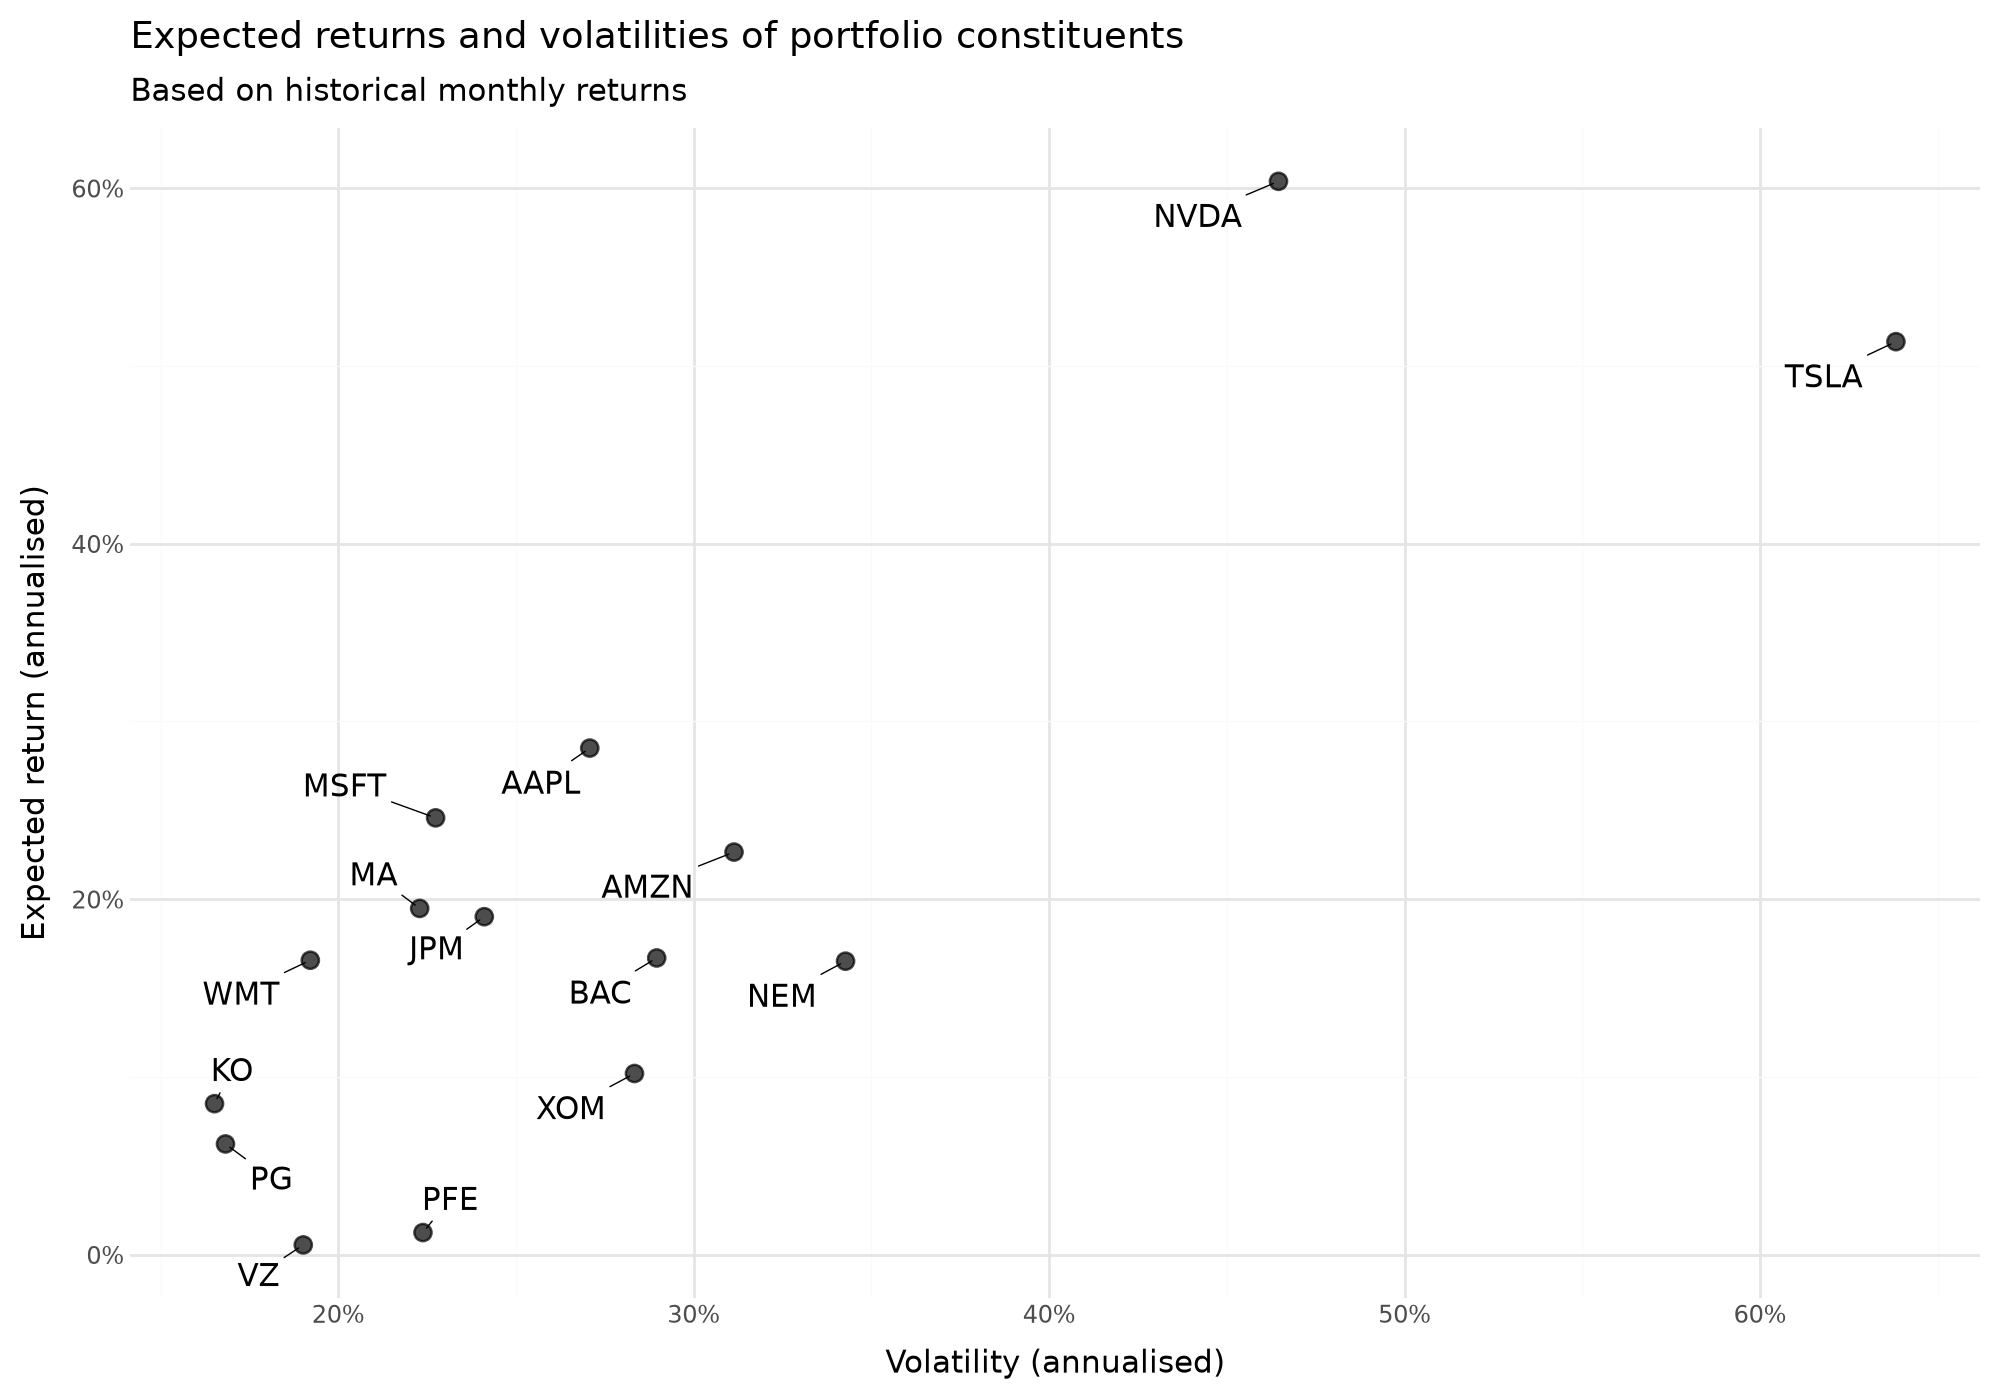

In [38]:
# Visualising the risk-return tradeoff
# Create asset summary with expected returns and volatilities
asset_summary = pd.DataFrame(
    {
        "symbol": summary_stats["symbol"],  # Stock ticker symbols
        "mu": summary_stats["mean"] * annualisation_factor,  # Arithmetic annualised mean
        "sigma": summary_stats["std"]
        * np.sqrt(annualisation_factor),  # Annualized volatility
    }
).reset_index(drop=True)

# Create enhanced scatter plot with better text positioning
assets_figure = (
    # Initialize plot with data and aesthetic mappings
    ggplot(asset_summary, aes(x="sigma", y="mu", label="symbol"))
    # Add points for each asset
    + geom_point(size=3, alpha=0.7)
    # Add text labels with automatic adjustment to prevent overlap
    + geom_text(adjust_text={"arrowprops": {"arrowstyle": "-"}})
    # Format x-axis as percentages
    + scale_x_continuous(labels=percent_format())
    # Format y-axis as percentages
    + scale_y_continuous(labels=percent_format())
    # Add informative labels
    + labs(
        x="Volatility (annualised)",
        y="Expected return (annualised)",
        title="Expected returns and volatilities of portfolio constituents",
        subtitle="Based on historical monthly returns",
    )
    # Use clean, professional theme
    + theme_minimal()
    # Set custom figure size
    + theme(figure_size=(10, 7))
)
# Display the plot
assets_figure

In [ ]:
# Estimating expected returns using the above graph
# Use the same monthly observations as the summary and scatter plot.
mu = expected_returns.mean_historical_return(
    returns_wide, returns_data=True, compounding=False,
    frequency=annualisation_factor,
)
pd.DataFrame({"expected_return": mu}).T

,AAPL,AMZN,BAC,JPM,KO,MA,MSFT,NEM,NVDA,PFE,PG,TSLA,VZ,WMT,XOM
expected_return,0.285012,0.2265,0.16693,0.190151,0.084955,0.194802,0.245754,0.165124,0.60387,0.012451,0.062297,0.513658,0.005489,0.165652,0.101932


In [40]:
# Look at how the stocks move together by calculating a sample covariance matrix (annualised)
# This captures both individual asset volatilities and co-movements between assets
cov_matrix = risk_models.sample_cov(
    returns_wide, returns_data=True, frequency=annualisation_factor
)
# Display the covariance matrix
cov_matrix

,AAPL,AMZN,BAC,JPM,KO,MA,MSFT,NEM,NVDA,PFE,PG,TSLA,VZ,WMT,XOM
AAPL,0.073301,0.044986,0.024578,0.015727,0.010539,0.027506,0.033514,0.007165,0.063748,0.015261,0.011932,0.090672,0.005482,0.013671,0.010966
AMZN,0.044986,0.096922,0.029845,0.017754,0.001983,0.027477,0.046606,0.003755,0.081271,0.006180,-0.000368,0.085490,0.003341,0.015825,0.007034
BAC,0.024578,0.029845,0.083852,0.063265,0.014312,0.032716,0.021522,-0.002435,0.047793,0.011255,0.007433,0.042576,0.010275,0.013204,0.040119
JPM,0.015727,0.017754,0.063265,0.058112,0.012084,0.026775,0.016822,-0.001674,0.036300,0.010839,0.005812,0.025455,0.008776,0.011549,0.030627
KO,0.010539,0.001983,0.014312,0.012084,0.027282,0.018226,0.007448,0.017189,-0.000971,0.009029,0.017151,0.003343,0.012699,0.010654,0.015272
MA,0.027506,0.027477,0.032716,0.026775,0.018226,0.049680,0.021457,0.003586,0.030594,0.007974,0.012213,0.033900,0.010992,0.010865,0.027270
MSFT,0.033514,0.046606,0.021522,0.016822,0.007448,0.021457,0.051698,0.006119,0.060106,0.008207,0.005686,0.049813,0.008948,0.009264,0.007050
NEM,0.007165,0.003755,-0.002435,-0.001674,0.017189,0.003586,0.006119,0.117442,-0.006424,0.024832,0.015913,0.029205,0.021802,0.009336,0.009167
NVDA,0.063748,0.081271,0.047793,0.036300,-0.000971,0.030594,0.060106,-0.006424,0.215760,0.012424,-0.000447,0.100340,0.008219,0.019418,0.012088
PFE,0.015261,0.006180,0.011255,0.010839,0.009029,0.007974,0.008207,0.024832,0.012424,0.050093,0.009012,0.012263,0.013281,0.008178,0.011967


In [41]:
# Long only efficient frontier and portfolios
# Initialize with expected returns (mu) and covariance matrix
ef_sharpe = EfficientFrontier(mu, cov_matrix)

# Maximum Sharpe ratio portfolio (tangency portfolio)
# This solves: max (mu_p - r_f) / sigma_p with the illustrative annual r_f = 2%
max_sharpe_weights = ef_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights: remove tiny positions (below threshold) for practical implementation
cleaned_max_sharpe = ef_sharpe.clean_weights()
# Calculate portfolio performance metrics (expected return, volatility, Sharpe ratio)
max_sharpe_perf = ef_sharpe.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MAXIMUM SHARPE RATIO PORTFOLIO")
print("=" * 50)
# Convert weights dictionary to DataFrame and sort by weight size
max_sharpe_weights_df = (
    pd.Series(cleaned_max_sharpe, name="weight").sort_values(ascending=False).to_frame()
)
# Create metrics series for cleaner display
max_sharpe_metrics = pd.Series(
    max_sharpe_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="max_sharpe_portfolio",
)
print("Portfolio weights:")
print(max_sharpe_weights_df)
print(f"\nPerformance metrics:")
print(max_sharpe_metrics)

Expected annual return: 31.1%
Annual volatility: 19.7%
Sharpe Ratio: 1.47

MAXIMUM SHARPE RATIO PORTFOLIO
Portfolio weights:
       weight
NVDA  0.25935
WMT   0.23081
NEM   0.14179
MA    0.11578
JPM   0.07996
MSFT  0.07540
AAPL  0.05972
TSLA  0.03719
KO    0.00000
AMZN  0.00000
BAC   0.00000
PG    0.00000
PFE   0.00000
VZ    0.00000
XOM   0.00000

Performance metrics:
expected_return    0.310673
volatility         0.197112
sharpe_ratio       1.474660
Name: max_sharpe_portfolio, dtype: float64


In [42]:
# Now find the minimum volatility portfolio weights where no short selling is allowed
# Create a fresh EfficientFrontier object (each optimization needs its own instance)
ef_min_vol = EfficientFrontier(mu, cov_matrix)
# Optimize for minimum volatility (ignores expected returns)
min_vol_weights = ef_min_vol.min_volatility()
# Clean up small weights for practical implementation
cleaned_min_vol = ef_min_vol.clean_weights()
# Calculate performance metrics
min_vol_perf = ef_min_vol.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MINIMUM VOLATILITY PORTFOLIO")
print("=" * 50)
# Convert weights to DataFrame and sort
min_vol_weights_df = (
    pd.Series(cleaned_min_vol, name="weight").sort_values(ascending=False).to_frame()
)
# Create metrics series
min_vol_metrics = pd.Series(
    min_vol_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="min_vol_portfolio",
)
print("Portfolio weights:")
print(min_vol_weights_df)
print(f"\nPerformance metrics:")
print(min_vol_metrics)

Expected annual return: 10.4%
Annual volatility: 12.0%
Sharpe Ratio: 0.70

MINIMUM VOLATILITY PORTFOLIO
Portfolio weights:
       weight
PG    0.20154
KO    0.17192
WMT   0.13841
PFE   0.12069
VZ    0.11508
MSFT  0.09631
JPM   0.05853
AMZN  0.05139
XOM   0.04297
NEM   0.00316
AAPL  0.00000
MA    0.00000
BAC   0.00000
NVDA  0.00000
TSLA  0.00000

Performance metrics:
expected_return    0.103561
volatility         0.120041
sharpe_ratio       0.696102
Name: min_vol_portfolio, dtype: float64


In [43]:
# Now comparing the long-only position to one with short-selling allowed
print("=" * 60)
print("COMPARING BOUNDED SHORT-SELLING VS. LONG-ONLY PORTFOLIOS")
print("=" * 60)

# =============================================================================
# BOUNDED SHORT-SELLING PORTFOLIOS (Allow short-selling)
# =============================================================================
print("\n" + "=" * 60)
print("BOUNDED SHORT-SELLING PORTFOLIOS (SHORT-SELLING ALLOWED)")
print("=" * 60)

# Maximum Sharpe with short-selling allowed
# weight_bounds=(-1, 1) means: -100% ≤ weight ≤ +100% for each asset
# Negative weights = short positions, Positive weights = long positions
ef_bounded_short_sharpe = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for maximum Sharpe ratio
bounded_short_sharpe_weights = ef_bounded_short_sharpe.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights (removes positions below threshold)
cleaned_bounded_short_sharpe = ef_bounded_short_sharpe.clean_weights()
# Calculate performance metrics
bounded_short_sharpe_perf = ef_bounded_short_sharpe.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMaximum Sharpe Portfolio (Bounded short-selling):")
bounded_short_sharpe_df = (
    pd.Series(cleaned_bounded_short_sharpe, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(bounded_short_sharpe_df)
print(f"\nExpected Return: {bounded_short_sharpe_perf[0]:.4f}")
print(f"Volatility: {bounded_short_sharpe_perf[1]:.4f}")
print(f"Sharpe Ratio: {bounded_short_sharpe_perf[2]:.4f}")

# Count short positions
num_shorts = sum(1 for w in cleaned_bounded_short_sharpe.values() if w < 0)
num_longs = sum(1 for w in cleaned_bounded_short_sharpe.values() if w > 0)
print(f"\nShort positions: {num_shorts} assets")
print(f"Long positions: {num_longs} assets")

# Minimum volatility with short-selling allowed
ef_bounded_short_minvol = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for minimum volatility
bounded_short_minvol_weights = ef_bounded_short_minvol.min_volatility()
# Clean weights
cleaned_bounded_short_minvol = ef_bounded_short_minvol.clean_weights()
# Calculate performance
bounded_short_minvol_perf = ef_bounded_short_minvol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMinimum Volatility Portfolio (Bounded short-selling):")
bounded_short_minvol_df = (
    pd.Series(cleaned_bounded_short_minvol, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(bounded_short_minvol_df)
print(f"\nExpected Return: {bounded_short_minvol_perf[0]:.4f}")
print(f"Volatility: {bounded_short_minvol_perf[1]:.4f}")
print(f"Sharpe Ratio: {bounded_short_minvol_perf[2]:.4f}")

# Count short positions
num_shorts_mv = sum(1 for w in cleaned_bounded_short_minvol.values() if w < 0)
num_longs_mv = sum(1 for w in cleaned_bounded_short_minvol.values() if w > 0)
print(f"\nShort positions: {num_shorts_mv} assets")
print(f"Long positions: {num_longs_mv} assets")

# =============================================================================
# LONG-ONLY PORTFOLIOS (No short-selling)
# =============================================================================
print("\n" + "=" * 60)
print("LONG-ONLY PORTFOLIOS (NO SHORT-SELLING)")
print("=" * 60)

# Maximum Sharpe with long-only constraint
# weight_bounds=(0, 1) means: 0 ≤ weight ≤ 1 for each asset (no shorts, no leverage)
ef_long_only = EfficientFrontier(mu, cov_matrix, weight_bounds=(0, 1))
# Optimize for maximum Sharpe ratio
long_only_sharpe_weights = ef_long_only.max_sharpe(risk_free_rate=risk_free_rate)
# Clean weights (removes positions below threshold)
cleaned_long_only_sharpe = ef_long_only.clean_weights()
# Calculate performance metrics
long_only_sharpe_perf = ef_long_only.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMaximum Sharpe Portfolio (Long-only):")
long_only_sharpe_df = (
    pd.Series(cleaned_long_only_sharpe, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(long_only_sharpe_df)
print(f"\nExpected Return: {long_only_sharpe_perf[0]:.4f}")
print(f"Volatility: {long_only_sharpe_perf[1]:.4f}")
print(f"Sharpe Ratio: {long_only_sharpe_perf[2]:.4f}")

# Minimum volatility with long-only constraint
ef_long_only_minvol = EfficientFrontier(mu, cov_matrix, weight_bounds=(0, 1))
# Optimize for minimum volatility
long_only_minvol_weights = ef_long_only_minvol.min_volatility()
# Clean weights
cleaned_long_only_minvol = ef_long_only_minvol.clean_weights()
# Calculate performance
long_only_minvol_perf = ef_long_only_minvol.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

print("\nMinimum Volatility Portfolio (Long-only):")
long_only_minvol_df = (
    pd.Series(cleaned_long_only_minvol, name="weight")
    .sort_values(ascending=False)
    .to_frame()
)
print("Weights:")
print(long_only_minvol_df)
print(f"\nExpected Return: {long_only_minvol_perf[0]:.4f}")
print(f"Volatility: {long_only_minvol_perf[1]:.4f}")
print(f"Sharpe Ratio: {long_only_minvol_perf[2]:.4f}")

# =============================================================================
# COMPARISON: Cost of constraints
# =============================================================================
print("\n" + "=" * 60)
print("IMPACT OF SHORT-SELLING CONSTRAINT")
print("=" * 60)

print("\nMaximum Sharpe Portfolio:")
print(
    f"  Bounded short-selling - Sharpe: {bounded_short_sharpe_perf[2]:.4f}, Vol: {bounded_short_sharpe_perf[1]:.4f}"
)
print(
    f"  Long-only     - Sharpe: {long_only_sharpe_perf[2]:.4f}, Vol: {long_only_sharpe_perf[1]:.4f}"
)
sharpe_loss = (
    (bounded_short_sharpe_perf[2] - long_only_sharpe_perf[2])
    / bounded_short_sharpe_perf[2]
) * 100
print(f"  → Sharpe ratio reduction: {sharpe_loss:.1f}%")

print("\nMinimum Volatility Portfolio:")
print(
    f"  Bounded short-selling - Vol: {bounded_short_minvol_perf[1]:.4f}, Return: {bounded_short_minvol_perf[0]:.4f}"
)
print(
    f"  Long-only     - Vol: {long_only_minvol_perf[1]:.4f}, Return: {long_only_minvol_perf[0]:.4f}"
)
vol_increase = (
    (long_only_minvol_perf[1] - bounded_short_minvol_perf[1])
    / bounded_short_minvol_perf[1]
) * 100
print(f"  → Volatility increase: {vol_increase:.1f}%")

COMPARING BOUNDED SHORT-SELLING VS. LONG-ONLY PORTFOLIOS

BOUNDED SHORT-SELLING PORTFOLIOS (SHORT-SELLING ALLOWED)

Maximum Sharpe Portfolio (Bounded short-selling):
Weights:
       weight
JPM   0.88483
WMT   0.44569
NVDA  0.38376
MSFT  0.32501
NEM   0.31886
AAPL  0.22396
MA    0.22144
XOM   0.14495
KO    0.08507
TSLA  0.04761
PG   -0.08101
AMZN -0.31274
PFE  -0.39632
VZ   -0.52954
BAC  -0.76156

Expected Return: 0.5489
Volatility: 0.2972
Sharpe Ratio: 1.7797

Short positions: 5 assets
Long positions: 10 assets

Minimum Volatility Portfolio (Bounded short-selling):
Weights:
       weight
JPM   0.29283
PG    0.21752
KO    0.17785
WMT   0.12090
PFE   0.10880
VZ    0.10573
AMZN  0.09927
MSFT  0.09582
XOM   0.07369
AAPL  0.00261
TSLA  0.00111
NEM  -0.00580
NVDA -0.01967
MA   -0.05053
BAC  -0.22015

Expected Return: 0.1017
Volatility: 0.1168
Sharpe Ratio: 0.6996

Short positions: 4 assets
Long positions: 11 assets

LONG-ONLY PORTFOLIOS (NO SHORT-SELLING)

Maximum Sharpe Portfolio (Long-only

In [ ]:
# Minimum volatility portfolio with bounded short-selling
# Create a fresh EfficientFrontier object (each optimization needs its own instance)
ef_min_vol = EfficientFrontier(mu, cov_matrix, weight_bounds=(-1, 1))
# Optimize for minimum volatility (ignores expected returns)
min_vol_weights = ef_min_vol.min_volatility()
# Clean up small weights for practical implementation
cleaned_min_vol = ef_min_vol.clean_weights()
# Calculate performance metrics
min_vol_perf = ef_min_vol.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate)

print("\n" + "=" * 50)
print("MINIMUM VOLATILITY PORTFOLIO (BOUNDED SHORT-SELLING)")
print("=" * 50)
# Convert weights to DataFrame and sort
min_vol_weights_df = (
    pd.Series(cleaned_min_vol, name="weight").sort_values(ascending=False).to_frame()
 )
# Create metrics series
min_vol_metrics = pd.Series(
    min_vol_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name="min_vol_portfolio",
)
print("Portfolio weights:")
print(min_vol_weights_df)
print(f"\nPerformance metrics:")
print(min_vol_metrics)

In [45]:
# Set a target return (clipped to feasible range for safety)
target_return = float(np.clip(mu.mean(), mu.min(), mu.max()))
# Create fresh EfficientFrontier object
ef_target = EfficientFrontier(mu, cov_matrix)
# Optimize to achieve target return with minimum risk
target_weights = ef_target.efficient_return(target_return=target_return)
# Clean weights
cleaned_target = ef_target.clean_weights()
# Calculate performance (verbose=False to suppress output)
target_perf = ef_target.portfolio_performance(verbose=False, risk_free_rate=risk_free_rate)

# Convert to DataFrames for display
target_weights_df = (
    pd.Series(cleaned_target, name="weight").sort_values(ascending=False).to_frame()
)
target_metrics = pd.Series(
    target_perf,
    index=["expected_return", "volatility", "sharpe_ratio"],
    name=f"target_return_{target_return:.2%}",
)
# Display weights and metrics
target_weights_df, target_metrics

(       weight
 WMT   0.22306
 KO    0.15074
 MSFT  0.14914
 PG    0.09636
 JPM   0.09246
 NVDA  0.08676
 NEM   0.08513
 AAPL  0.04396
 XOM   0.03752
 MA    0.02842
 TSLA  0.00643
 AMZN  0.00000
 BAC   0.00000
 PFE   0.00000
 VZ    0.00000,
 expected_return    0.201638
 volatility         0.138526
 sharpe_ratio       1.311218
 Name: target_return_20.16%, dtype: float64)

In [51]:
def compute_frontier_points(mu_vec, cov, weight_bounds):
    """Trace the efficient upper branch under the specified position bounds."""
    minimum = EfficientFrontier(mu_vec, cov, weight_bounds=weight_bounds)
    minimum.min_volatility()
    minimum_return = minimum.portfolio_performance(
        risk_free_rate=risk_free_rate
    )[0]

    # Maximise a linear expected return subject to the same position bounds.
    weights = cp.Variable(len(mu_vec))
    maximum = cp.Problem(cp.Maximize(mu_vec.to_numpy() @ weights), [
        cp.sum(weights) == 1,
        weights >= weight_bounds[0], weights <= weight_bounds[1],
    ])
    maximum.solve(solver=cp.OSQP, max_iter=100_000)
    if maximum.status not in {cp.OPTIMAL, cp.OPTIMAL_INACCURATE}:
        raise RuntimeError(f"Maximum-return calculation failed: {maximum.status}")

    target_margin = max(1e-4, abs(float(maximum.value)) * 1e-4)
    targets = np.linspace(minimum_return, float(maximum.value) - target_margin, 25)
    rows = []
    for target in targets:
        ef = EfficientFrontier(
            mu_vec,
            cov,
            weight_bounds=weight_bounds,
            solver=cp.OSQP,
            solver_options={"max_iter": 100_000},
        )
        ef.efficient_return(float(target))
        perf = ef.portfolio_performance(risk_free_rate=risk_free_rate)
        rows.append({"target_return": target, "expected_return": perf[0],
                     "volatility": perf[1], "sharpe_ratio": perf[2]})
    return pd.DataFrame(rows)


frontier_bounded_short = compute_frontier_points(mu, cov_matrix, (-1, 1))
frontier_long_only = compute_frontier_points(mu, cov_matrix, (0, 1))
frontier_bounded_short["constraint_type"] = "Bounded short-selling"
frontier_long_only["constraint_type"] = "Long-only"
all_frontiers = pd.concat([frontier_bounded_short, frontier_long_only], ignore_index=True)

# Individual asset positions (for reference on plot)
asset_positions = pd.DataFrame(
    {
        "symbol": mu.index,
        "expected_return": mu,
        "volatility": np.sqrt(np.diag(cov_matrix)),  # Square root of variance
    }
).reset_index(drop=True)

# Key portfolios with different constraints (for annotation on plot)
key_portfolios = pd.DataFrame(
    [
        {
            "portfolio": "Min vol (short)",
            "expected_return": bounded_short_minvol_perf[0],
            "volatility": bounded_short_minvol_perf[1],
            "constraint_type": "Bounded short-selling",
        },
        {
            "portfolio": "Max Sharpe (short)",
            "expected_return": bounded_short_sharpe_perf[0],
            "volatility": bounded_short_sharpe_perf[1],
            "constraint_type": "Bounded short-selling",
        },
        {
            "portfolio": "Target (Long-only)",
            "expected_return": target_perf[0],
            "volatility": target_perf[1],
            "constraint_type": "Long-only",
        },
        {
            "portfolio": "Min Vol (Long-only)",
            "expected_return": long_only_minvol_perf[0],
            "volatility": long_only_minvol_perf[1],
            "constraint_type": "Long-only",
        },
        {
            "portfolio": "Max Sharpe (Long-only)",
            "expected_return": long_only_sharpe_perf[0],
            "volatility": long_only_sharpe_perf[1],
            "constraint_type": "Long-only",
        },
    ]
).reset_index(drop=True)

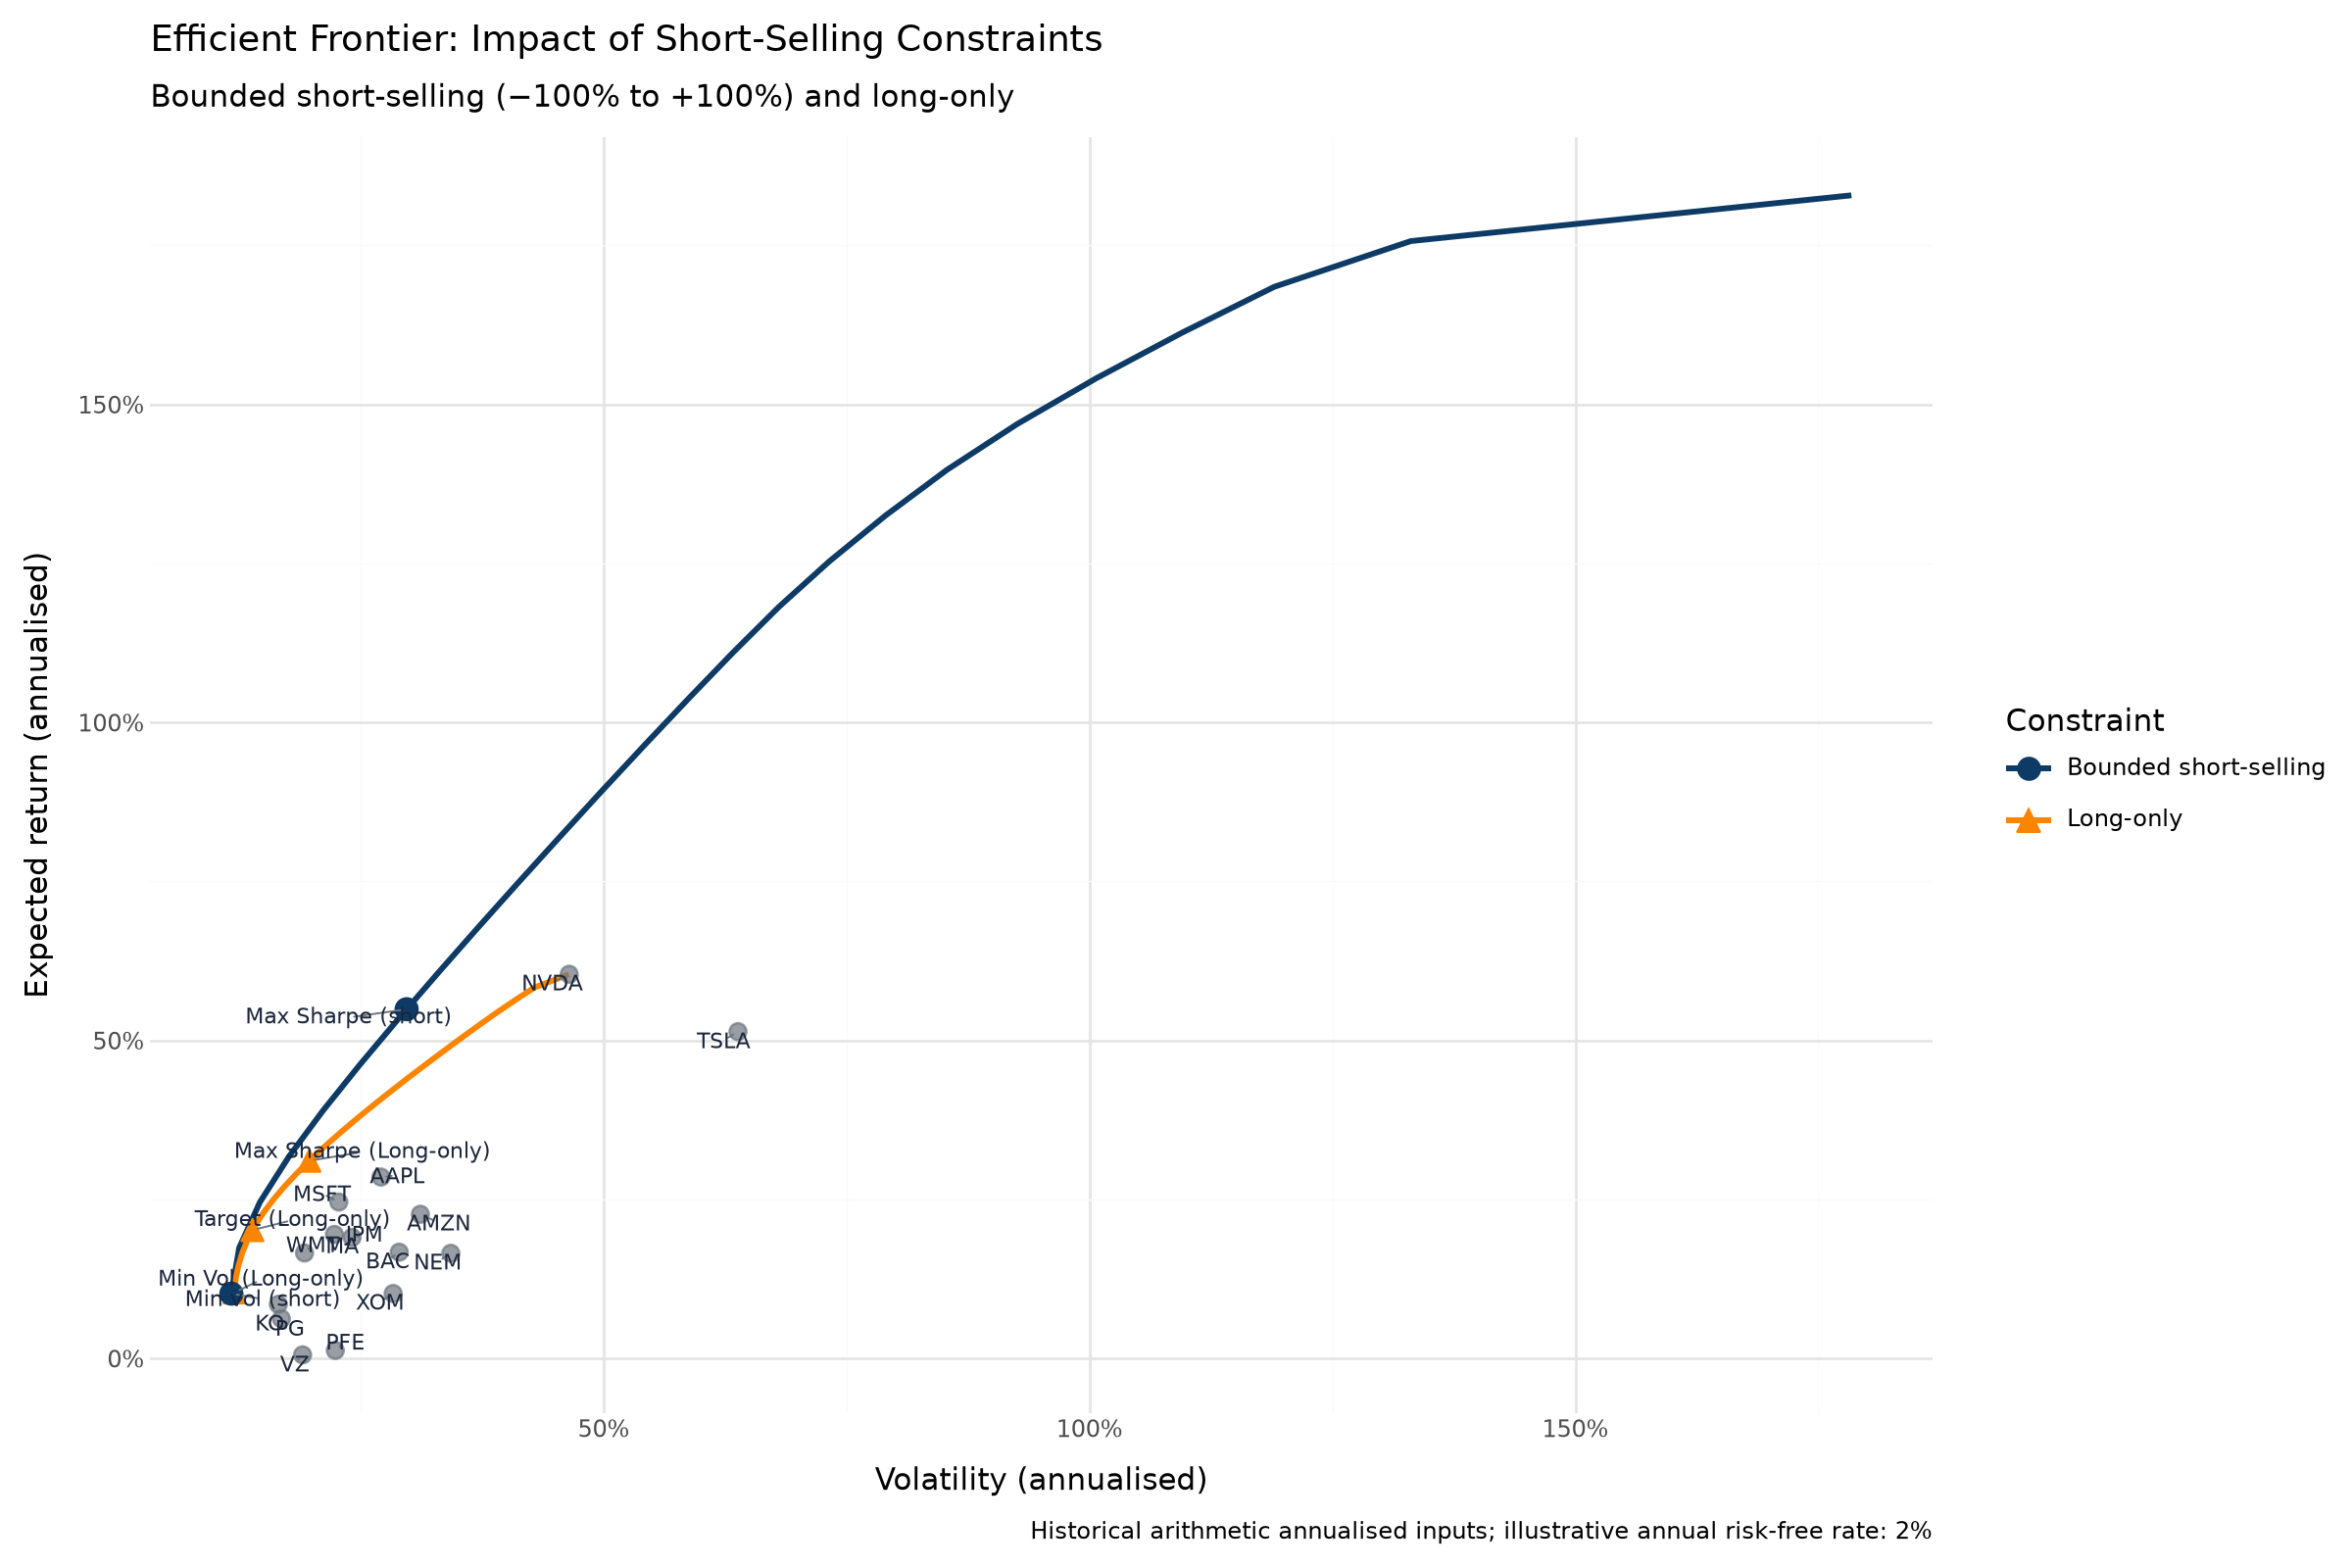

In [52]:
# Adjust all labels together so asset and portfolio labels avoid each other.
plot_labels = pd.concat([
    asset_positions.rename(columns={"symbol": "label"}),
    key_portfolios.rename(columns={"portfolio": "label"}),
], ignore_index=True)
np.random.seed(3318)  # Reproducible initial displacement of overlapping labels

enhanced_plot = (
    ggplot()
    + geom_line(
        all_frontiers,
        aes(x="volatility", y="expected_return", color="constraint_type"),
        size=1.2,
    )
    + geom_point(
        asset_positions, aes(x="volatility", y="expected_return"),
        color="#6c757d", size=3, alpha=0.7,
    )
    + geom_point(
        key_portfolios,
        aes(x="volatility", y="expected_return", color="constraint_type",
            shape="constraint_type"), size=4,
    )
    + geom_text(
        plot_labels, aes(x="volatility", y="expected_return", label="label"),
        size=8, color="#1b263b",
        adjust_text={
            "arrowprops": {"arrowstyle": "-", "color": "#6c757d", "lw": 0.7},
            "expand": (1.3, 1.5), "force_text": (0.6, 0.9),
            "force_static": (0.4, 0.5), "force_pull": (0.005, 0.005),
            "iter_lim": 1000,
        },
    )
    + scale_x_continuous(labels=percent_format())
    + scale_y_continuous(labels=percent_format())
    + scale_color_manual(values={"Bounded short-selling": "#0d3b66", "Long-only": "#fb8500"})
    + scale_shape_manual(values={"Bounded short-selling": "o", "Long-only": "^"})
    + labs(
        title="Efficient Frontier: Impact of Short-Selling Constraints",
        subtitle="Bounded short-selling (−100% to +100%) and long-only",
        x="Volatility (annualised)", y="Expected return (annualised)",
        color="Constraint", shape="Constraint",
        caption="Historical arithmetic annualised inputs; illustrative annual risk-free rate: 2%",
    )
    + theme_minimal()
    + theme(figure_size=(12, 8))
)
enhanced_plot


PORTFOLIO WEIGHTS COMPARISON
Portfolio weights summary:
      Max Sharpe (Short)  Min Vol (Short)  Max Sharpe (Long)  Min Vol (Long)
AAPL             0.22396          0.00261            0.05972         0.00000
AMZN            -0.31274          0.09927            0.00000         0.05139
BAC             -0.76156         -0.22015            0.00000         0.00000
JPM              0.88483          0.29283            0.07996         0.05853
KO               0.08507          0.17785            0.00000         0.17192
MA               0.22144         -0.05053            0.11578         0.00000
MSFT             0.32501          0.09582            0.07540         0.09631
NEM              0.31886         -0.00580            0.14179         0.00316
NVDA             0.38376         -0.01967            0.25935         0.00000
PFE             -0.39632          0.10880            0.00000         0.12069
PG              -0.08101          0.21752            0.00000         0.20154
TSLA             0.

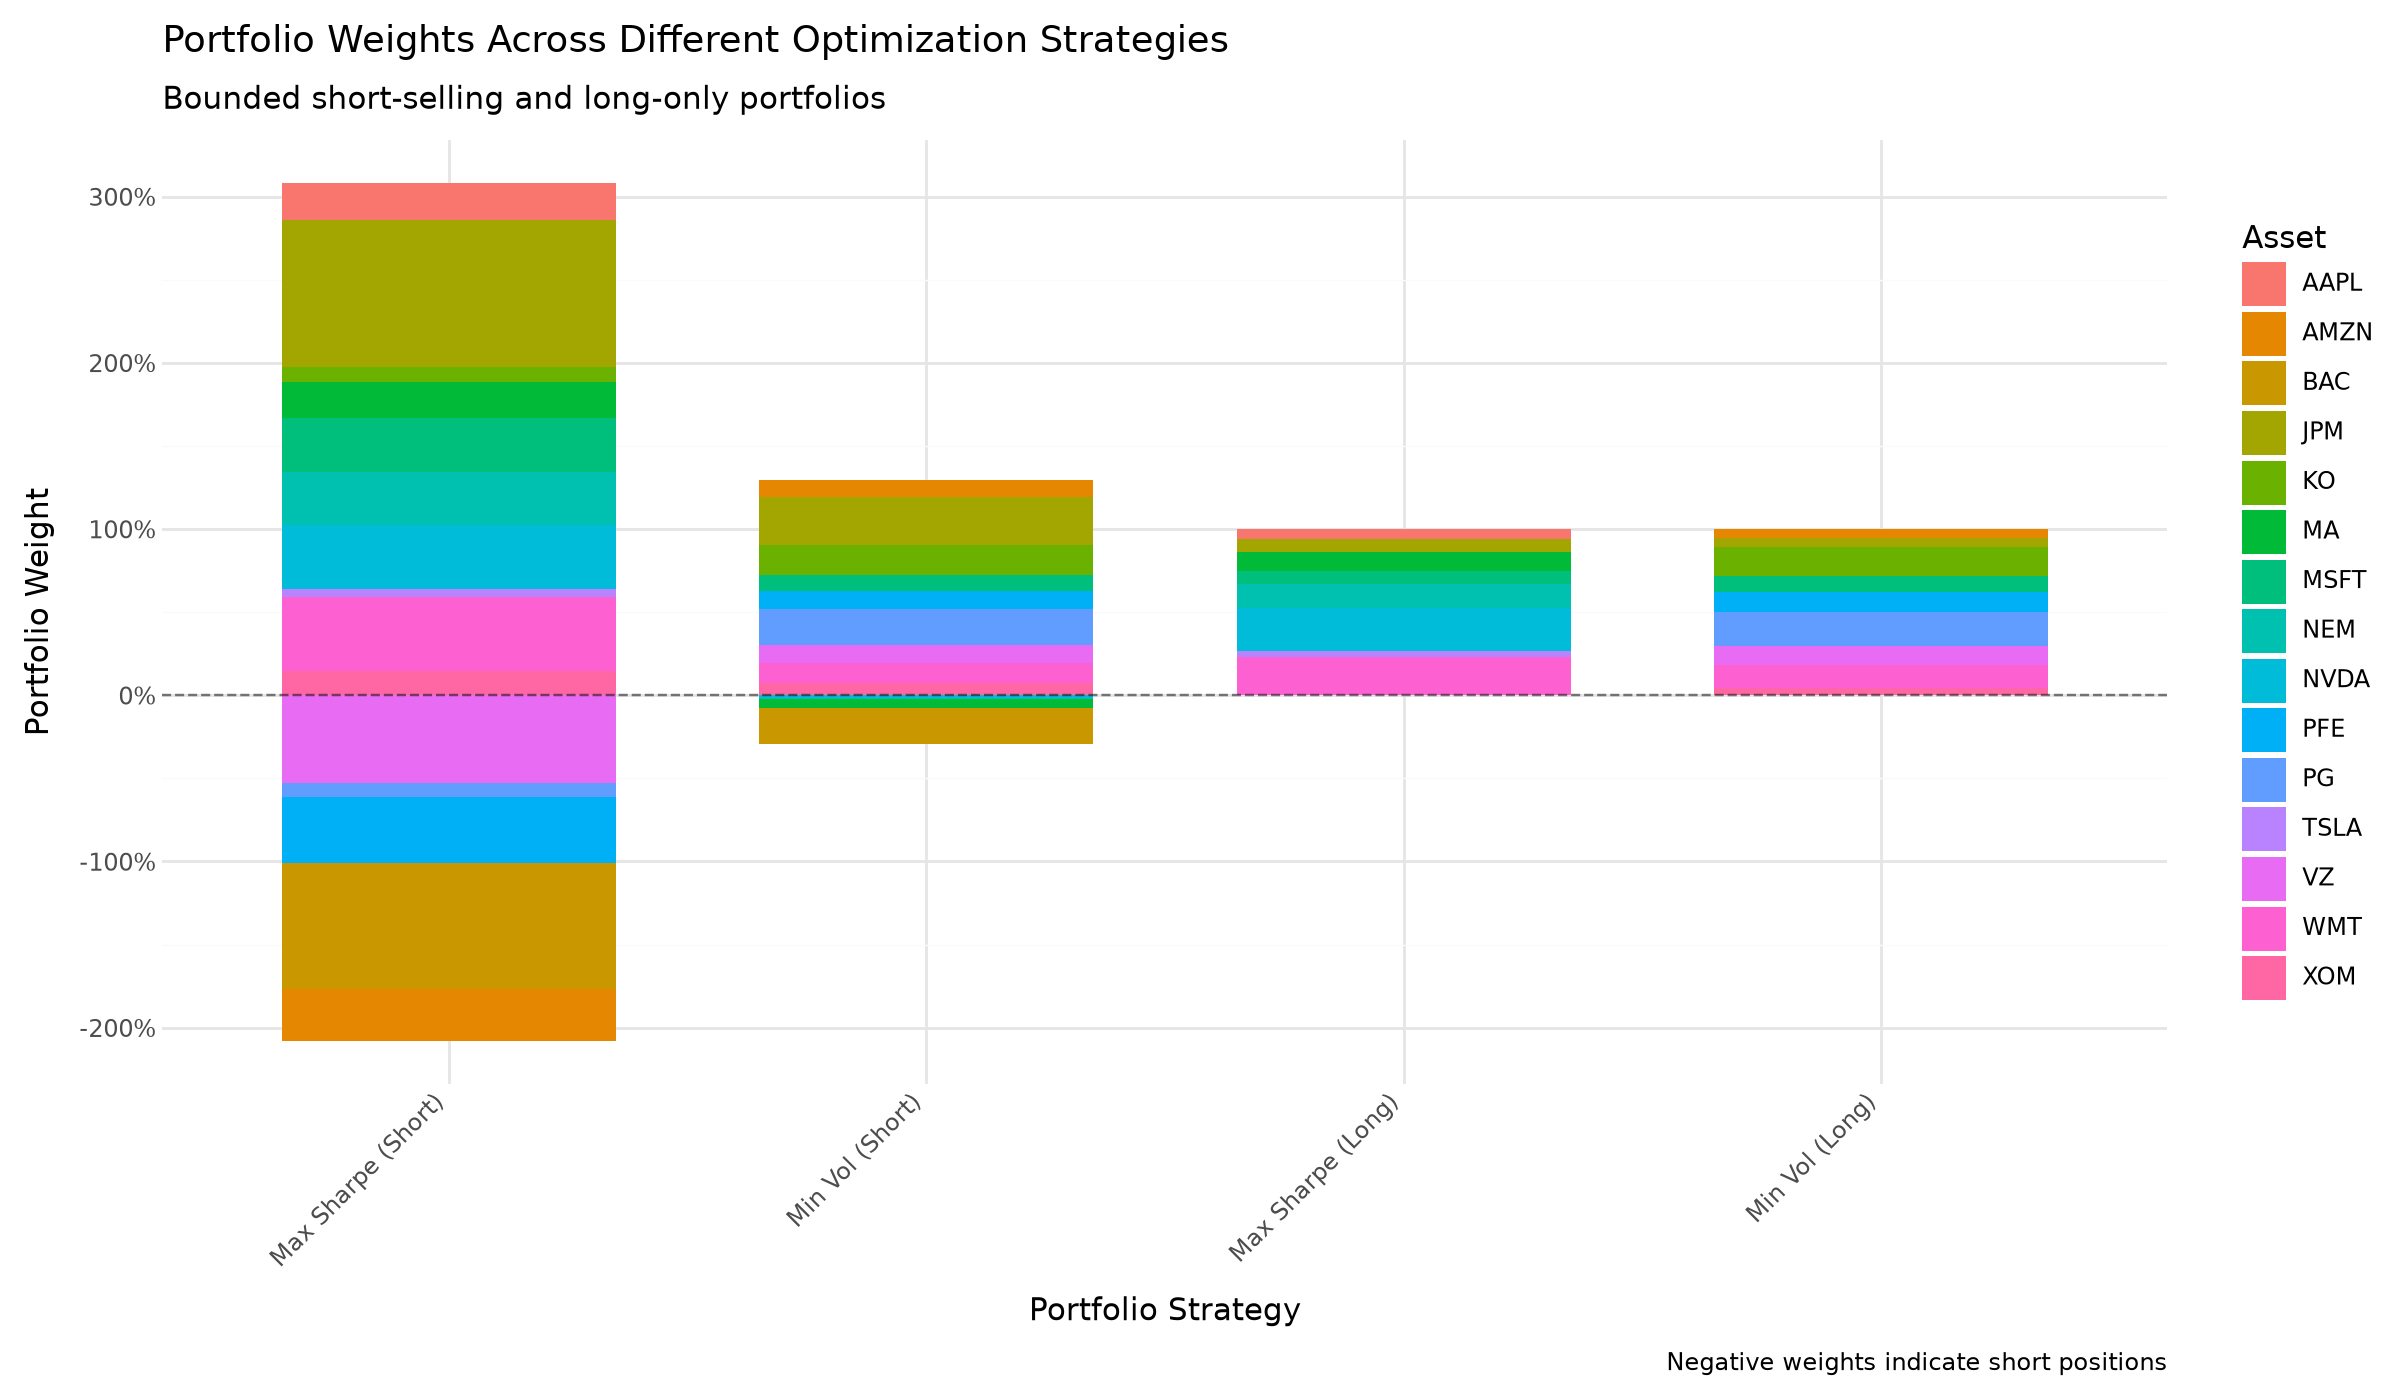

In [54]:
# Portfolio weights comparison visualization
print("\n" + "=" * 50)
print("PORTFOLIO WEIGHTS COMPARISON")
print("=" * 50)

# Compile all portfolio weights (excluding custom constraints for now)
# Each column represents one portfolio strategy
weights_comparison = pd.DataFrame(
    {
        "Max Sharpe (Short)": pd.Series(
            cleaned_bounded_short_sharpe
        ),  # Maximum Sharpe, bounded_short
        "Min Vol (Short)": pd.Series(
            cleaned_bounded_short_minvol
        ),  # Minimum volatility, bounded_short
        "Max Sharpe (Long)": pd.Series(
            cleaned_long_only_sharpe
        ),  # Maximum Sharpe, long-only
        "Min Vol (Long)": pd.Series(
            cleaned_long_only_minvol
        ),  # Minimum volatility, long-only
    }
).fillna(
    0
)  # Replace NaN with 0 (assets not included in portfolio)

print("Portfolio weights summary:")
print(weights_comparison)

# Create stacked bar chart with better styling
# Reshape data from wide to long format for ggplot
weights_long = (
    weights_comparison.reset_index()
    .melt(id_vars="index", var_name="Portfolio", value_name="Weight")
    .rename(columns={"index": "Asset"})
)

# Add constraint type for coloring
weights_long["Constraint_Type"] = weights_long["Portfolio"].apply(
    lambda x: "Long-only" if "Long" in x else "Bounded short-selling"
)

# Sort portfolios for better display (explicit ordering)
weights_long["Portfolio"] = pd.Categorical(
    weights_long["Portfolio"],
    categories=[
        "Max Sharpe (Short)",
        "Min Vol (Short)",
        "Max Sharpe (Long)",
        "Min Vol (Long)",
    ],
    ordered=True,
)

# Create stacked bar chart
weights_plot = (
    ggplot(weights_long, aes(x="Portfolio", y="Weight", fill="Asset"))
    # Stacked bars showing composition of each portfolio
    + geom_col(position="stack", width=0.7)
    # Add horizontal line at zero to clearly show short positions
    + geom_hline(yintercept=0, linetype="dashed", color="black", alpha=0.5)
    # Format y-axis as percentages
    + scale_y_continuous(labels=percent_format())
    # Add comprehensive labels
    + labs(
        title="Portfolio Weights Across Different Optimization Strategies",
        subtitle="Bounded short-selling and long-only portfolios",
        x="Portfolio Strategy",
        y="Portfolio Weight",
        caption="Negative weights indicate short positions",
    )
    # Use minimal theme
    + theme_minimal()
    # Rotate x-axis labels for readability
    + theme(
        axis_text_x=element_text(angle=45, hjust=1),
        figure_size=(12, 7),
        legend_position="right",
    )
    # Customize legend
    + guides(fill=guide_legend(title="Asset"))
)

# Display the plot
weights_plot